In [1]:
import pandas as pd
df = pd.read_csv("PC_Uncertainty_dataset.csv")

In [2]:
df

,Gross Electrical Output (MWg),As-Delivered Primary Fuel Cost ($/ton),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg),Important Performance & Cost Factors: CO2 Removed (tons/hr),Important Performance & Cost Factors: Net Electrical Output (MW),Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton)
0,1534.0,48.900002,38.299999,60.877499,3.6775,868.279724,1336.483643,159.369995
1,2122.0,45.500000,35.700001,87.982498,4.8325,1722.348755,1825.054810,110.072769
2,1498.0,67.300003,42.900002,62.437500,1.5075,869.229858,1337.637817,166.645416
3,418.0,31.700001,28.700001,89.542503,4.5175,345.206390,360.549957,139.354156
4,1666.0,57.500000,11.500000,64.387497,1.5775,996.329956,1486.579224,159.967117
...,...,...,...,...,...,...,...,...
195,202.0,58.099998,38.700001,70.432503,2.4175,131.969788,178.349472,223.930115
196,1462.0,61.500000,31.100000,87.592499,5.1475,1181.545776,1252.625000,122.992653
197,646.0,60.900002,48.700001,66.142502,4.4475,396.695221,557.657959,178.050934
198,262.0,37.900002,29.900000,62.827499,7.4925,153.009171,218.053696,219.787796


In [3]:
df.isna().sum()

Gross Electrical Output (MWg)                                       0
As-Delivered Primary Fuel Cost ($/ton)                              0
Cooling Water Temperature Rise (°F)                                 0
Absorber CO2 Removal Efficiency (%)                                 0
Amine Scrubber Power Requirement (% MWg)                            0
Important Performance & Cost Factors: CO2 Removed (tons/hr)         0
Important Performance & Cost Factors: Net Electrical Output (MW)    0
Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton)       0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
x = df[['Gross Electrical Output (MWg)',
    'As-Delivered Primary Fuel Cost ($/ton)',
    'Cooling Water Temperature Rise (°F)',
    'Absorber CO2 Removal Efficiency (%)',
    'Amine Scrubber Power Requirement (% MWg)']]

y = df['Important Performance & Cost Factors: Net Electrical Output (MW)']

In [6]:
x

,Gross Electrical Output (MWg),As-Delivered Primary Fuel Cost ($/ton),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg)
0,1534.0,48.900002,38.299999,60.877499,3.6775
1,2122.0,45.500000,35.700001,87.982498,4.8325
2,1498.0,67.300003,42.900002,62.437500,1.5075
3,418.0,31.700001,28.700001,89.542503,4.5175
4,1666.0,57.500000,11.500000,64.387497,1.5775
...,...,...,...,...,...
195,202.0,58.099998,38.700001,70.432503,2.4175
196,1462.0,61.500000,31.100000,87.592499,5.1475
197,646.0,60.900002,48.700001,66.142502,4.4475
198,262.0,37.900002,29.900000,62.827499,7.4925


In [7]:
y

0      1336.483643
1      1825.054810
2      1337.637817
3       360.549957
4      1486.579224
          ...     
195     178.349472
196    1252.625000
197     557.657959
198     218.053696
199     542.019653
Name: Important Performance & Cost Factors: Net Electrical Output (MW), Length: 200, dtype: float64

In [8]:
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("\n=== FINAL SHAP MODEL ===\n")


=== FINAL SHAP MODEL ===



In [11]:
# Gradient Boosting Regressor
gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {
        "n_estimators": [100, 300],
        "max_depth": [3, 6, 10],
        "learning_rate": [0.01, 0.1, 0.3],
        "subsample": [0.8, 1.0],
        "max_features": [0.8, 1.0]
    },
    cv=5, scoring="r2", n_jobs=-1
)
gbr_grid.fit(x_train, y_train)

best_gbr = gbr_grid.best_estimator_
print("Gradient Boosting best params:", gbr_grid.best_params_)
print('Train R2:', best_gbr.score(x_train, y_train))
print('Test R2:', best_gbr.score(x_test, y_test))

Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 3, 'max_features': 1.0, 'n_estimators': 300, 'subsample': 0.8}
Train R2: 0.9999984875419187
Test R2: 0.9990602281538901


In [12]:
#Checking the RMSE and MAPE scores
from sklearn.metrics import mean_squared_error
import numpy as np

print("\n=== RMSE & MAPE ===\n")

models = {
    'Gradient Boost':    best_gbr
}

for name, model in models.items():
    y_pred = model.predict(x_test)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))
    mape   = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    print(f"{name} | RMSE: {rmse:.4f} | MAPE: {mape:.4f}%")


=== RMSE & MAPE ===

Gradient Boost | RMSE: 19.5244 | MAPE: 2.7903%


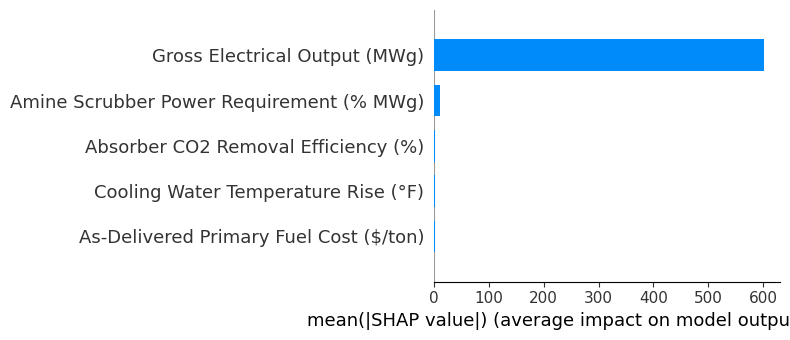

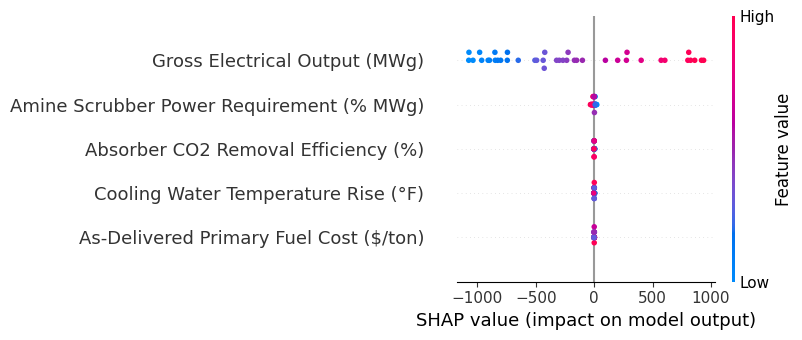

Dependence plot for: Gross Electrical Output (MWg)


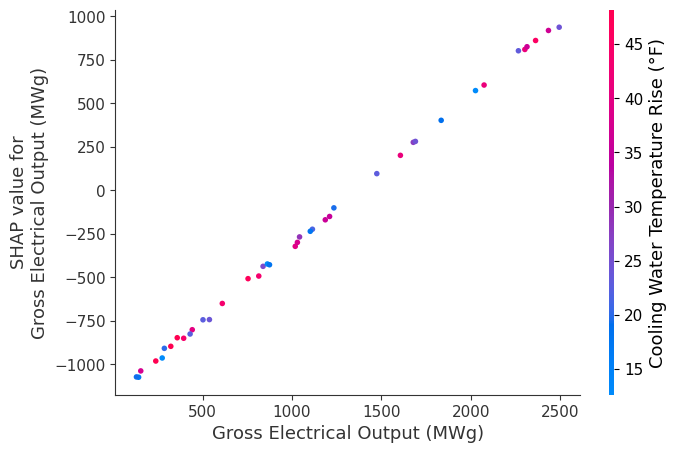

Dependence plot for: Amine Scrubber Power Requirement (% MWg)


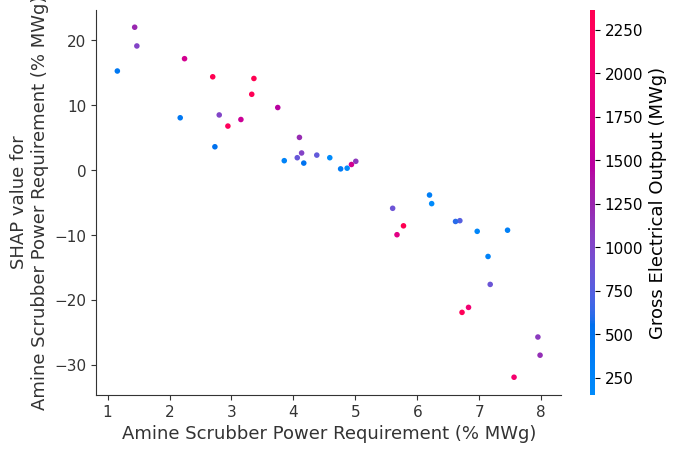

In [15]:
import shap
import numpy as np

explainer   = shap.TreeExplainer(best_gbr)
shap_values = explainer.shap_values(x_test)

# 1. BAR — overall driver ranking (mean |SHAP|)
shap.summary_plot(shap_values, x_test, plot_type="bar")

# 2. BEESWARM — direction + magnitude per feature
shap.summary_plot(shap_values, x_test)

# 3. DEPENDENCE — auto-pick the top driver(s), no manual editing per target
mean_abs = np.abs(shap_values).mean(axis=0)          # per-feature importance
order    = np.argsort(mean_abs)[::-1]                 # most -> least important
for i in order[:2]:                                   # top 2 drivers
    print("Dependence plot for:", x_test.columns[i])
    shap.dependence_plot(x_test.columns[i], shap_values, x_test)